In [69]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns 
import plotly.graph_objects as go

df=pd.read_csv("/kaggle/input/datasets/fahmidachowdhury/e-commerce-sales-analysis")

In [70]:
ds=df.copy()

## **DATASET EXPLORATION**

In [71]:
df

,product_id,product_name,category,price,review_score,review_count,sales_month_1,sales_month_2,sales_month_3,sales_month_4,sales_month_5,sales_month_6,sales_month_7,sales_month_8,sales_month_9,sales_month_10,sales_month_11,sales_month_12
0,1,Product_1,Clothing,190.40,1.7,220,479,449,92,784,604,904,446,603,807,252,695,306
1,2,Product_2,Home & Kitchen,475.60,3.2,903,21,989,861,863,524,128,610,436,176,294,772,353
2,3,Product_3,Toys,367.34,4.5,163,348,558,567,143,771,409,290,828,340,667,267,392
3,4,Product_4,Toys,301.34,3.9,951,725,678,59,15,937,421,670,933,56,157,168,203
4,5,Product_5,Books,82.23,4.2,220,682,451,649,301,620,293,411,258,854,548,770,257
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,996,Product_996,Home & Kitchen,50.33,3.6,494,488,359,137,787,678,970,282,155,57,575,634,393
996,997,Product_997,Home & Kitchen,459.07,4.8,701,18,906,129,78,19,110,403,683,104,858,729,474
997,998,Product_998,Sports,72.73,1.3,287,725,109,193,657,215,337,664,476,265,344,888,654
998,999,Product_999,Sports,475.37,1.2,720,196,191,315,622,854,122,65,938,521,268,60,394


In [72]:
df.head(5)

,product_id,product_name,category,price,review_score,review_count,sales_month_1,sales_month_2,sales_month_3,sales_month_4,sales_month_5,sales_month_6,sales_month_7,sales_month_8,sales_month_9,sales_month_10,sales_month_11,sales_month_12
0,1,Product_1,Clothing,190.40,1.7,220,479,449,92,784,604,904,446,603,807,252,695,306
1,2,Product_2,Home & Kitchen,475.60,3.2,903,21,989,861,863,524,128,610,436,176,294,772,353
2,3,Product_3,Toys,367.34,4.5,163,348,558,567,143,771,409,290,828,340,667,267,392
3,4,Product_4,Toys,301.34,3.9,951,725,678,59,15,937,421,670,933,56,157,168,203
4,5,Product_5,Books,82.23,4.2,220,682,451,649,301,620,293,411,258,854,548,770,257


### **Column Description**
1. **product_name** – Name of the product.
2. **category** – Category or type the product belongs to (e.g., electronics, clothing, etc.).
3. **price** – Price of the product (in float, meaning it can have decimal values).
4. **review_score** – Average rating given by customers, usually on a scale (e.g., 1–5).
5. **review_count** – Total number of reviews received for the product.
6. **sales_month_1** to **sales_month_12** – Number of units sold in each month.

sales_month_1 = sales in the first month of the dataset period.

sales_month_2 = sales in the second month, and so on until month 12.

All are integers representing product sales volume.

In [73]:
df.columns

Index(['product_id', 'product_name', 'category', 'price', 'review_score',
       'review_count', 'sales_month_1', 'sales_month_2', 'sales_month_3',
       'sales_month_4', 'sales_month_5', 'sales_month_6', 'sales_month_7',
       'sales_month_8', 'sales_month_9', 'sales_month_10', 'sales_month_11',
       'sales_month_12'],
      dtype='object')

In [74]:
df.shape

(1000, 18)

In [75]:
df.isna().sum()

product_id        0
product_name      0
category          0
price             0
review_score      0
review_count      0
sales_month_1     0
sales_month_2     0
sales_month_3     0
sales_month_4     0
sales_month_5     0
sales_month_6     0
sales_month_7     0
sales_month_8     0
sales_month_9     0
sales_month_10    0
sales_month_11    0
sales_month_12    0
dtype: int64

In [76]:
df.duplicated().sum()

np.int64(0)

In [77]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 18 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   product_id      1000 non-null   int64  
 1   product_name    1000 non-null   object 
 2   category        1000 non-null   object 
 3   price           1000 non-null   float64
 4   review_score    1000 non-null   float64
 5   review_count    1000 non-null   int64  
 6   sales_month_1   1000 non-null   int64  
 7   sales_month_2   1000 non-null   int64  
 8   sales_month_3   1000 non-null   int64  
 9   sales_month_4   1000 non-null   int64  
 10  sales_month_5   1000 non-null   int64  
 11  sales_month_6   1000 non-null   int64  
 12  sales_month_7   1000 non-null   int64  
 13  sales_month_8   1000 non-null   int64  
 14  sales_month_9   1000 non-null   int64  
 15  sales_month_10  1000 non-null   int64  
 16  sales_month_11  1000 non-null   int64  
 17  sales_month_12  1000 non-null   in

In [78]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
product_id,1000.0,500.50000,288.819436,1.00,250.75,500.50,750.250,1000.00
price,1000.0,247.67713,144.607983,7.29,121.81,250.92,373.435,499.86
review_score,1000.0,3.02760,1.171243,1.00,2.00,3.10,4.000,5.00
review_count,1000.0,526.50600,282.269932,1.00,283.75,543.00,772.000,999.00
sales_month_1,1000.0,498.30600,289.941478,0.00,245.50,507.50,740.750,1000.00
sales_month_2,1000.0,507.66100,285.992689,2.00,262.50,508.00,756.250,1000.00
sales_month_3,1000.0,506.73900,294.010873,0.00,243.75,493.00,777.250,999.00
sales_month_4,1000.0,503.82300,286.645567,0.00,261.50,501.50,749.500,1000.00
sales_month_5,1000.0,487.19400,287.844324,0.00,221.00,497.00,727.000,1000.00
sales_month_6,1000.0,491.65300,289.234018,0.00,236.00,479.50,740.500,1000.00


In [79]:
cols=['product_name', 'category', 'price', 'review_score', 'review_count',
       'sales_month_1', 'sales_month_2', 'sales_month_3', 'sales_month_4',
       'sales_month_5', 'sales_month_6', 'sales_month_7', 'sales_month_8',
       'sales_month_9', 'sales_month_10', 'sales_month_11', 'sales_month_12']

for col in cols:
    print(f"{col}:    {df[col].nunique()}")

product_name:    1000
category:    7
price:    992
review_score:    41
review_count:    620
sales_month_1:    634
sales_month_2:    629
sales_month_3:    630
sales_month_4:    640
sales_month_5:    627
sales_month_6:    639
sales_month_7:    628
sales_month_8:    643
sales_month_9:    632
sales_month_10:    637
sales_month_11:    632
sales_month_12:    632


In [80]:
print("Unique Categories in the dataset")
df['category'].unique().tolist()

Unique Categories in the dataset


['Clothing',
 'Home & Kitchen',
 'Toys',
 'Books',
 'Electronics',
 'Health',
 'Sports']

In [81]:
Cols=['category', 'review_score']

print("Frequency of Unique Values in 'Category' and 'Review Score' column")
for col in Cols:
    print(df[col].value_counts())

Frequency of Unique Values in 'Category' and 'Review Score' column
category
Books             154
Sports            153
Toys              151
Clothing          140
Health            139
Electronics       138
Home & Kitchen    125
Name: count, dtype: int64
review_score
4.5    39
3.5    35
3.8    32
3.6    32
1.9    31
1.3    31
3.9    30
4.9    29
1.7    29
1.5    29
4.1    28
4.2    28
2.8    27
1.4    27
1.1    26
3.2    26
1.2    25
2.6    25
2.7    25
3.4    24
2.4    24
3.0    24
4.4    23
2.0    23
4.3    23
4.7    23
3.1    23
3.7    22
4.0    21
2.9    21
4.8    21
2.3    21
2.2    20
2.1    20
5.0    19
3.3    18
1.6    18
2.5    17
1.8    17
1.0    12
4.6    12
Name: count, dtype: int64


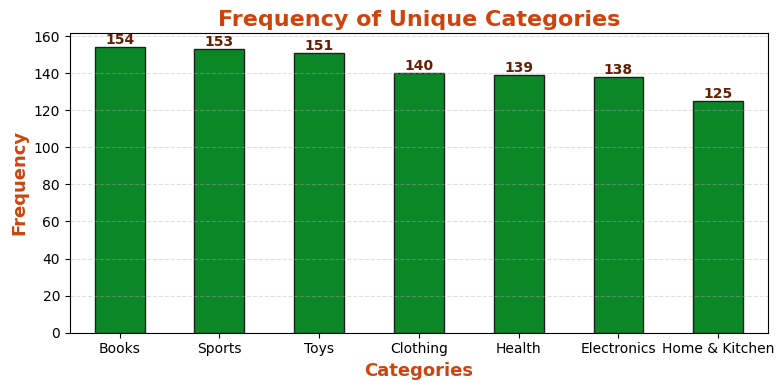

In [82]:
count=df['category'].value_counts()
ax=count.plot(kind='bar',figsize=(8,4),color="#0C8728",edgecolor="#1D211D")
plt.title('Frequency of Unique Categories',fontsize=16,color="#CD440E",fontweight='bold',pad=5.0)
plt.xlabel('Categories',fontsize=13,color="#CD440E",fontweight='bold')
plt.ylabel('Frequency',fontsize=13,color="#CD440E",fontweight='bold')
plt.xticks(rotation=0,fontsize=10)
plt.yticks(rotation=0,fontsize=10)

# Add labels on top of bars
for p in ax.patches:
    ax.annotate(str(int(p.get_height())),  # Convert height to integer string
                (p.get_x() + p.get_width() / 2, p.get_height()),  # Position
                ha='center', va='bottom', fontsize=10, fontweight='bold', color="#651F03")
    
#ax.patches → gets each bar in the chart.
# p.get_height() → the height of the bar (the count).
# ax.annotate() → places text on top of each bar.

plt.grid(axis='y',linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()


In [83]:
# Set product_id as index 
df.set_index('product_id',inplace=True)

## **EXPLORATORY DATA ANALYSIS**

**What is the Sales Volume in each month?**

In [84]:
Monthly_sales=df[['sales_month_1', 'sales_month_2', 'sales_month_3', 'sales_month_4',
       'sales_month_5', 'sales_month_6', 'sales_month_7', 'sales_month_8',
       'sales_month_9', 'sales_month_10', 'sales_month_11', 'sales_month_12']].sum()
Monthly_sales


sales_month_1     498306
sales_month_2     507661
sales_month_3     506739
sales_month_4     503823
sales_month_5     487194
sales_month_6     491653
sales_month_7     507011
sales_month_8     504569
sales_month_9     491934
sales_month_10    514798
sales_month_11    505838
sales_month_12    500386
dtype: int64

* [['col1', 'col2', ...]] → selects multiple columns as a DataFrame.

* .sum() → by default, sums down each column, so you get total sales per month.

In [85]:
# Another way 
sales_by_month=df.loc[:, 'sales_month_1':'sales_month_12'].sum()
sales_by_month

sales_month_1     498306
sales_month_2     507661
sales_month_3     506739
sales_month_4     503823
sales_month_5     487194
sales_month_6     491653
sales_month_7     507011
sales_month_8     504569
sales_month_9     491934
sales_month_10    514798
sales_month_11    505838
sales_month_12    500386
dtype: int64

In [86]:
Months=['Jan','Feb','March','April','May','June','July','August','Sept','Oct','Nov','Dec']
Months

['Jan',
 'Feb',
 'March',
 'April',
 'May',
 'June',
 'July',
 'August',
 'Sept',
 'Oct',
 'Nov',
 'Dec']

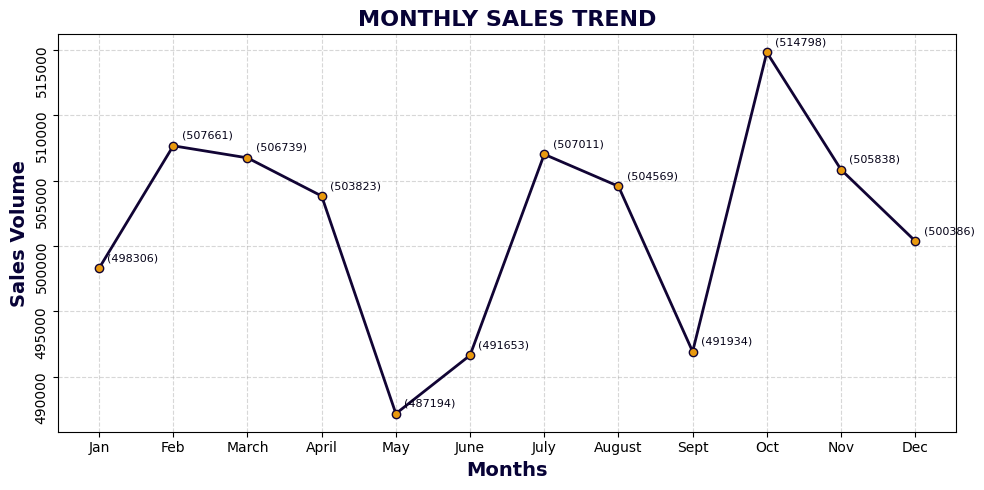

In [87]:
plt.figure(figsize=(10,5))
plt.plot(Months,Monthly_sales,color="#110434",linewidth=2,marker='o',markerfacecolor="#E9990E",markersize=6)
plt.title("MONTHLY SALES TREND",fontweight='bold',fontsize=16,color="#070236")
plt.xlabel('Months',fontsize=14,color="#070236",fontweight='bold')
plt.ylabel('Sales Volume',fontsize=14,color="#070236",fontweight='bold')
plt.xticks(rotation=0, fontsize=10)
plt.yticks(rotation=90, fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)

# Show x and y values on each point
for x, y in zip(Months, Monthly_sales):
    plt.annotate(f"({y})",  # Text showing both coordinates
                 (x, y),          # Position at the point
                 textcoords="offset points",  # Offset for better visibility
                 xytext=(6, 5),   # Shift label slightly above point
                 ha='left', fontsize=8, color="#040117")
plt.tight_layout()
plt.show()

**INSIGHTS**
* Sales are decreasing from April to May.
* Sales are much higher during **Winter** Season from Sept to Dec and Jan to March.

**How much Revenue is generated each month?**

`Formula:` Revenue by each Product in each Month= Units sold in that month * Price of each unit

In [88]:
# Total Revenue per month 
Revenue={}

for month in range(1,13):
    Revenue[f"Month_{month}"]=(df[f'sales_month_{month}']*df['price']).sum()

Revenue

{'Month_1': np.float64(122000733.6),
 'Month_2': np.float64(125612977.65),
 'Month_3': np.float64(124522146.85),
 'Month_4': np.float64(126631427.28),
 'Month_5': np.float64(121915316.69),
 'Month_6': np.float64(119622249.86),
 'Month_7': np.float64(124397921.75),
 'Month_8': np.float64(123082579.08999999),
 'Month_9': np.float64(121499224.32),
 'Month_10': np.float64(129100593.25999999),
 'Month_11': np.float64(125617151.0),
 'Month_12': np.float64(124701861.67)}

In [89]:
# Convert Dictionary to list or DataFrame for Plotting
M=list(Revenue.keys())
Revenue_Monthly=list(Revenue.values())

#ds=pd.DataFrame(list(Revenue.items()),columns=['M','Revenue_Monthly'])



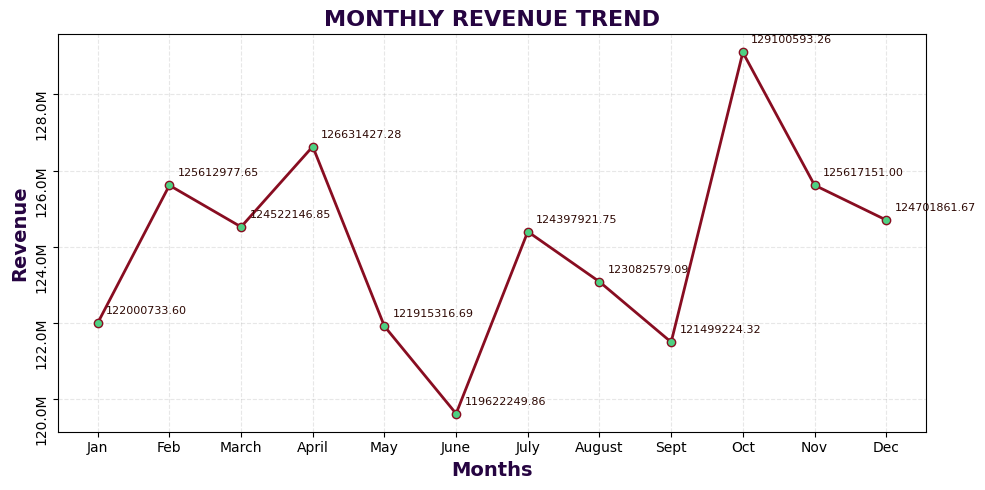

In [90]:
plt.figure(figsize=(10,5))
plt.plot(Months,Revenue_Monthly,color="#880D21",linewidth=2,marker='o',markerfacecolor="#4ED082",markersize=6)
plt.title("MONTHLY REVENUE TREND",fontweight='bold',fontsize=16,color="#260441")
plt.xlabel('Months',fontsize=14,color="#260441",fontweight='bold')
plt.ylabel('Revenue',fontsize=14,color="#260441",fontweight='bold')
plt.xticks(rotation=0, fontsize=10)
plt.yticks(rotation=90, fontsize=10)
plt.grid(True, linestyle='--', alpha=0.3)

# Y-axis formatting: convert to millions
def to_millions(x, pos):
    return f'{x * 1e-6:.1f}M'

plt.gca().yaxis.set_major_formatter(ticker.FuncFormatter(to_millions))

# Show x and y values on each point
for x, y in zip(Months, Revenue_Monthly):
    plt.annotate(f"{y:.2f}",  # Text showing both coordinates
                 (x, y),          # Position at the point
                 textcoords="offset points",  # Offset for better visibility
                 xytext=(6, 5),   # Shift label slightly above point
                 ha='left',va='bottom', fontsize=8, color="#2D0803")
plt.tight_layout()
plt.show()

**INSIGHTS**
* Revenue generated from October to December is very high.During **Winter** Season,the company has made lot of profit.
* Revenue generated after April to June is very low.During **Summer** season, the revenue generation is less indicating very less units are sold as compared to other months.

**How different Categories have performed over time?**

In [91]:
Category_wise_sales=df.groupby('category')[
    [f'sales_month_{m}' for m in range(1,13)]
].sum()

Category_wise_sales

,sales_month_1,sales_month_2,sales_month_3,sales_month_4,sales_month_5,sales_month_6,sales_month_7,sales_month_8,sales_month_9,sales_month_10,sales_month_11,sales_month_12
category,,,,,,,,,,,,
Books,77932,80079,76998,74699,79051,76644,79114,78108,77211,83504,76557,78332
Clothing,60966,67911,76796,70088,61643,63123,66105,74422,72675,68806,71683,72318
Electronics,76347,72472,70708,73158,72169,70060,72223,65754,69914,70148,68148,64019
Health,67644,67432,67602,72925,69178,63926,75256,69126,64581,72613,72500,71631
Home & Kitchen,57844,57252,62667,65388,59766,63169,60129,65042,58135,64876,66281,61592
Sports,77737,82244,75109,74287,73467,75641,77082,73912,79209,80187,74270,73226
Toys,79836,80271,76859,73278,71920,79090,77102,78205,70209,74664,76399,79268


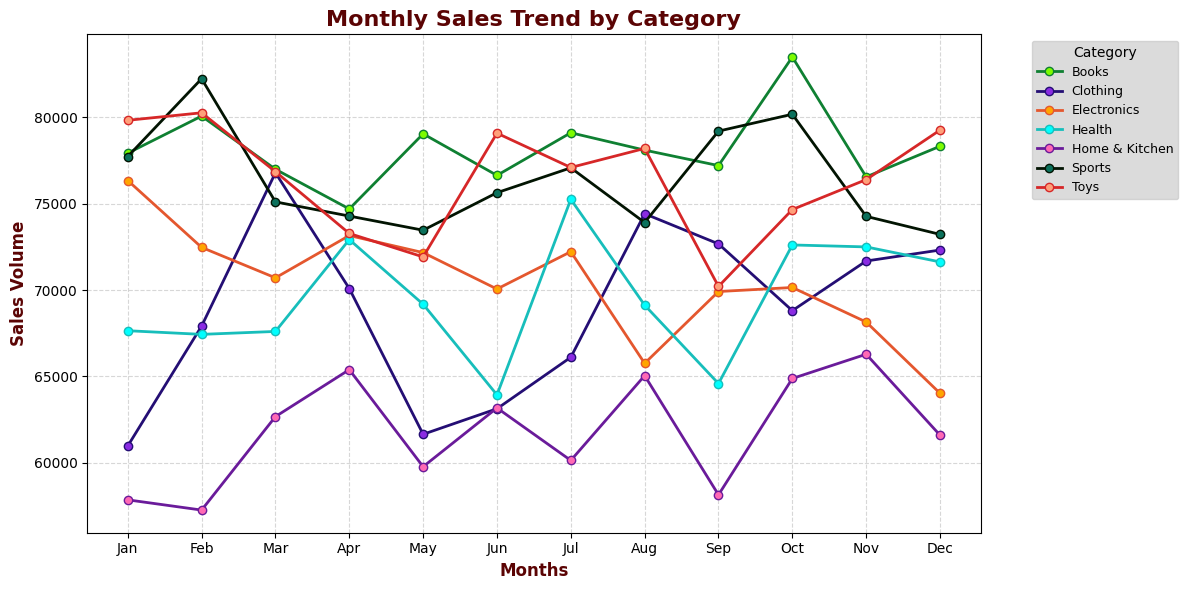

In [92]:
months_names = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 
                'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

# Plot line chart
plt.figure(figsize=(12,6))
# Plot each commodity line
colors = [
    '#0F8032',  # Deep Green
    '#240E74',  # Dark Indigo
    '#E4572E',  # Burnt Orange
    '#17BEBB',  # Teal Blue
    '#6A1B9A',  # Deep Purple
    "#021402",  # Green
    '#d62728',  # Red
]

marker_colors = [
    '#7CFC00',  # Lawn Green
    '#8A2BE2',  # Blue Violet
    '#FFA500',  # Orange
    '#00FFFF',  # Aqua
    '#FF69B4',  # Hot Pink
    "#0B715C",  # Mint Green
    '#FFA07A',  # Light Salmon
]

for i,category in enumerate(Category_wise_sales.index):
    plt.plot(
        months_names,
        Category_wise_sales.loc[category],
        marker='o',
        markerfacecolor=marker_colors[i % len(marker_colors)],
        color=colors[i % len(colors)],
        linewidth=2,
        label=category

    )

# Title & labels
plt.title("Monthly Sales Trend by Category", fontsize=16, fontweight='bold', color="#5B0404")
plt.xlabel("Months", fontsize=12, fontweight='bold', color="#5B0404")
plt.ylabel("Sales Volume", fontsize=12, fontweight='bold', color="#5B0404")

# Grid, legend, and layout
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(title="Category",fontsize=9,bbox_to_anchor=(1.05, 1), loc='upper left',frameon=True,facecolor='lightgray')
plt.tight_layout()
plt.show()

**Which Category has given the highest sales over the Past year?**

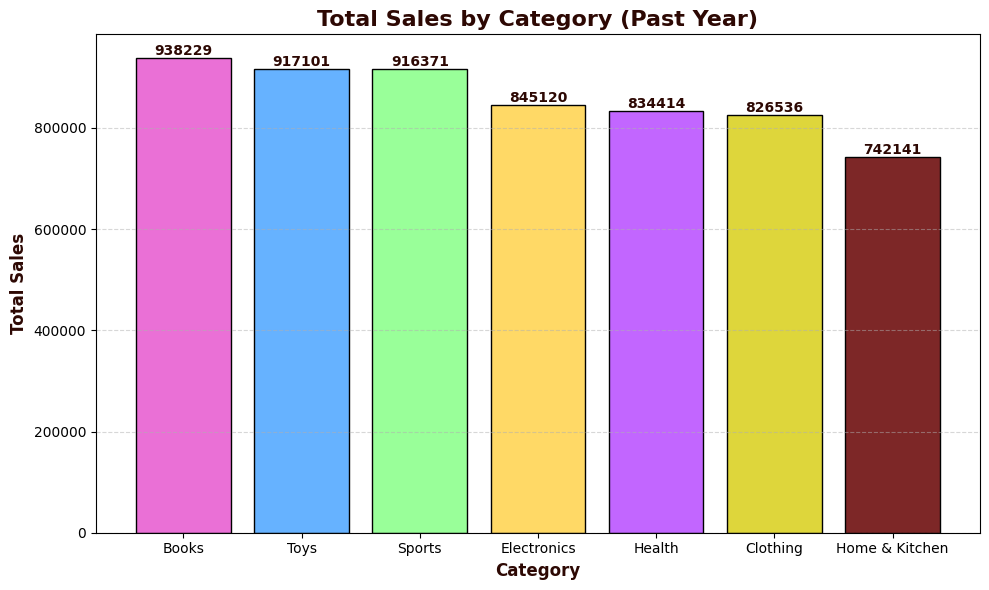

In [93]:
# Calculate total sales for each category across all months
Category_total_sales = Category_wise_sales.sum(axis=1).sort_values(ascending=False)

# Custom colors
bar_colors = ["#EA70D6", "#66B2FF", "#99FF99", "#FFD966", "#C266FF", "#DED63B", "#7D2727"]

plt.figure(figsize=(10, 6))
bars = plt.bar(
    Category_total_sales.index,
    Category_total_sales.values,
    color=bar_colors,
    edgecolor="black"
)

# Title and labels
plt.title("Total Sales by Category (Past Year)", fontsize=16, fontweight='bold', color="#2D0803")
plt.xlabel("Category", fontsize=12, fontweight='bold', color="#2D0803")
plt.ylabel("Total Sales", fontsize=12, fontweight='bold', color="#2D0803")

# Add values on top of bars
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2, height,
        f"{height:.0f}",
        ha='center', va='bottom',
        fontsize=10, fontweight='bold', color="#2D0803"
    )

# Grid
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

**Which Category has received the highest and lowest Average Rating by the Customers?**

In [94]:
avg_rating=df.groupby('category')['review_score'].mean()
avg_rating

category
Books             3.096753
Clothing          2.952143
Electronics       3.143478
Health            3.005036
Home & Kitchen    3.035200
Sports            3.091503
Toys              2.870861
Name: review_score, dtype: float64

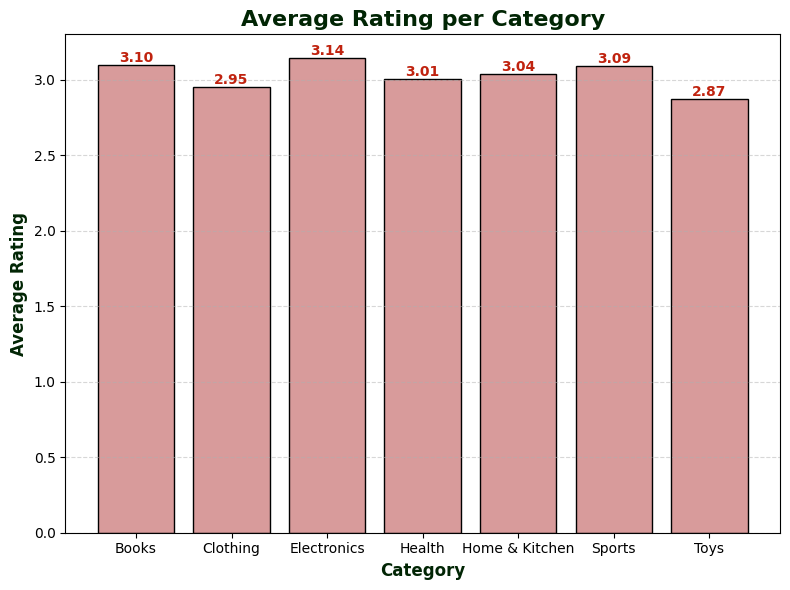

In [95]:

plt.figure(figsize=(8,6))
bars = plt.bar(avg_rating.index, avg_rating.values, color="#D89B9B", edgecolor="black")

# Labels & Title
plt.title("Average Rating per Category", fontsize=16, fontweight='bold', color="#012504")
plt.xlabel("Category", fontsize=12, fontweight='bold', color="#012504")
plt.ylabel("Average Rating", fontsize=12, fontweight='bold', color="#012504")

# Show values on bars
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, height,
             f"{height:.2f}", ha='center', va='bottom', fontsize=10, fontweight='bold', color="#C0230F")

plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

**Which category is the most expensive and which one is least expensive?**

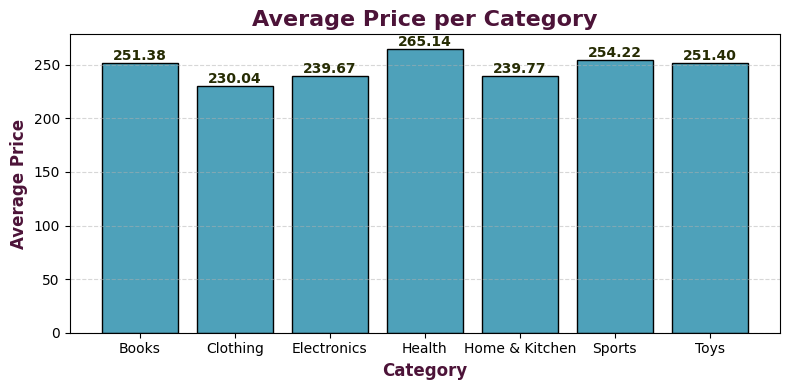

In [96]:
average_price=df.groupby('category')['price'].mean()

plt.figure(figsize=(8,4))
bars = plt.bar(average_price.index, average_price.values, color="#4EA1BA", edgecolor="black")

# Labels & Title
plt.title("Average Price per Category", fontsize=16, fontweight='bold', color="#4C1338")
plt.xlabel("Category", fontsize=12, fontweight='bold', color="#4C1338")
plt.ylabel("Average Price", fontsize=12, fontweight='bold', color="#4C1338")

# Show values on bars
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, height,
             f"{height:.2f}", ha='center', va='bottom', fontsize=10, fontweight='bold', color="#262C03")

plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

**For each month, find out what percentage of total company revenue came from each category?**

In [97]:
#Create Product level revenue columns per month

for month in range(1,13):
    df[f"Revenue_Product_month{month}"]=df[f'sales_month_{month}']*df['price']

df.filter(items=['Revenue_Product_month1',
       'Revenue_Product_month2', 'Revenue_Product_month3',
       'Revenue_Product_month4', 'Revenue_Product_month5',
       'Revenue_Product_month6', 'Revenue_Product_month7',
       'Revenue_Product_month8', 'Revenue_Product_month9',
       'Revenue_Product_month10', 'Revenue_Product_month11',
       'Revenue_Product_month12'])

#sales_month_1 = 479 units
#price = 190.40
#revenue_month_1 (Product level)= 479 × 190.40 = 91,601.6


,Revenue_Product_month1,Revenue_Product_month2,Revenue_Product_month3,Revenue_Product_month4,Revenue_Product_month5,Revenue_Product_month6,Revenue_Product_month7,Revenue_Product_month8,Revenue_Product_month9,Revenue_Product_month10,Revenue_Product_month11,Revenue_Product_month12
product_id,,,,,,,,,,,,
1,91201.60,85489.60,17516.80,149273.60,115001.60,172121.60,84918.40,114811.20,153652.80,47980.80,132328.00,58262.40
2,9987.60,470368.40,409491.60,410442.80,249214.40,60876.80,290116.00,207361.60,83705.60,139826.40,367163.20,167886.80
3,127834.32,204975.72,208281.78,52529.62,283219.14,150242.06,106528.60,304157.52,124895.60,245015.78,98079.78,143997.28
4,218471.50,204308.52,17779.06,4520.10,282355.58,126864.14,201897.80,281150.22,16875.04,47310.38,50625.12,61172.02
5,56080.86,37085.73,53367.27,24751.23,50982.60,24093.39,33796.53,21215.34,70224.42,45062.04,63317.10,21133.11
...,...,...,...,...,...,...,...,...,...,...,...,...
996,24561.04,18068.47,6895.21,39609.71,34123.74,48820.10,14193.06,7801.15,2868.81,28939.75,31909.22,19779.69
997,8263.26,415917.42,59220.03,35807.46,8722.33,50497.70,185005.21,313544.81,47743.28,393882.06,334662.03,217599.18
998,52729.25,7927.57,14036.89,47783.61,15636.95,24510.01,48292.72,34619.48,19273.45,25019.12,64584.24,47565.42


In [98]:
category_monthly_revenue=df.groupby('category')[
 [f"Revenue_Product_month{m}" for m in range(1,13)]
].sum()

category_monthly_revenue

,Revenue_Product_month1,Revenue_Product_month2,Revenue_Product_month3,Revenue_Product_month4,Revenue_Product_month5,Revenue_Product_month6,Revenue_Product_month7,Revenue_Product_month8,Revenue_Product_month9,Revenue_Product_month10,Revenue_Product_month11,Revenue_Product_month12
category,,,,,,,,,,,,
Books,19485930.49,19957691.89,20162437.50,18956014.31,20609636.73,18964252.96,20429337.59,18868303.09,19109771.26,21504710.23,19100834.20,19633885.35
Clothing,13436025.66,16420644.09,17012233.41,16403848.20,14414173.94,14118954.22,14605376.70,16583879.19,16208453.53,15565661.47,15584494.54,16904575.90
Electronics,18110207.88,16775555.86,16927992.70,17839634.69,16572709.86,16821513.69,16973996.24,15471864.65,17190807.23,17210046.73,16479785.97,15300568.57
Health,18045325.41,17615618.57,17980688.77,19133268.96,18773000.08,16400220.86,20455210.91,18360092.15,16634507.88,20046905.23,19658148.53,18633864.78
Home & Kitchen,14038194.28,13298977.75,14498643.41,16433015.24,14147352.23,14524429.34,14442992.50,16470170.43,14098116.81,15366884.79,16101030.92,14945697.56
Sports,19055982.27,21129563.51,18612262.68,19044637.08,19240937.78,19109221.53,18729059.99,17796405.80,20509356.26,21070603.60,19358695.20,18992106.18
Toys,19829067.61,20414925.98,19327888.38,18821008.80,18157506.07,19683657.26,18761947.82,19531863.78,17748211.35,18335781.21,19334161.64,20291163.33


In [99]:
# Column-wise division by total revenue of that month
category_monthly_percentage = category_monthly_revenue.div(
    category_monthly_revenue.sum(axis=0), axis=1
) * 100
category_monthly_percentage

,Revenue_Product_month1,Revenue_Product_month2,Revenue_Product_month3,Revenue_Product_month4,Revenue_Product_month5,Revenue_Product_month6,Revenue_Product_month7,Revenue_Product_month8,Revenue_Product_month9,Revenue_Product_month10,Revenue_Product_month11,Revenue_Product_month12
category,,,,,,,,,,,,
Books,15.971978,15.888240,16.191849,14.969439,16.904879,15.853449,16.422571,15.329792,15.728307,16.657329,15.205594,15.744661
Clothing,11.013070,13.072411,13.662014,12.954010,11.823103,11.802950,11.740853,13.473783,13.340376,12.057002,12.406343,13.555993
Electronics,14.844343,13.354954,13.594363,14.087841,13.593624,14.062195,13.644919,12.570312,14.148903,13.330726,13.119057,12.269719
Health,14.791161,14.023725,14.439752,15.109416,15.398393,13.710009,16.443370,14.916889,13.691040,15.528128,15.649255,14.942732
Home & Kitchen,11.506647,10.587264,11.643426,12.977043,11.604245,12.141913,11.610317,13.381399,11.603462,11.903032,12.817542,11.985144
Sports,15.619564,16.821163,14.946950,15.039424,15.782215,15.974638,15.055766,14.458915,16.880236,16.321074,15.410869,15.230010
Toys,16.253236,16.252243,15.521647,14.862826,14.893540,16.454846,15.082204,15.868910,14.607675,14.202709,15.391339,16.271741


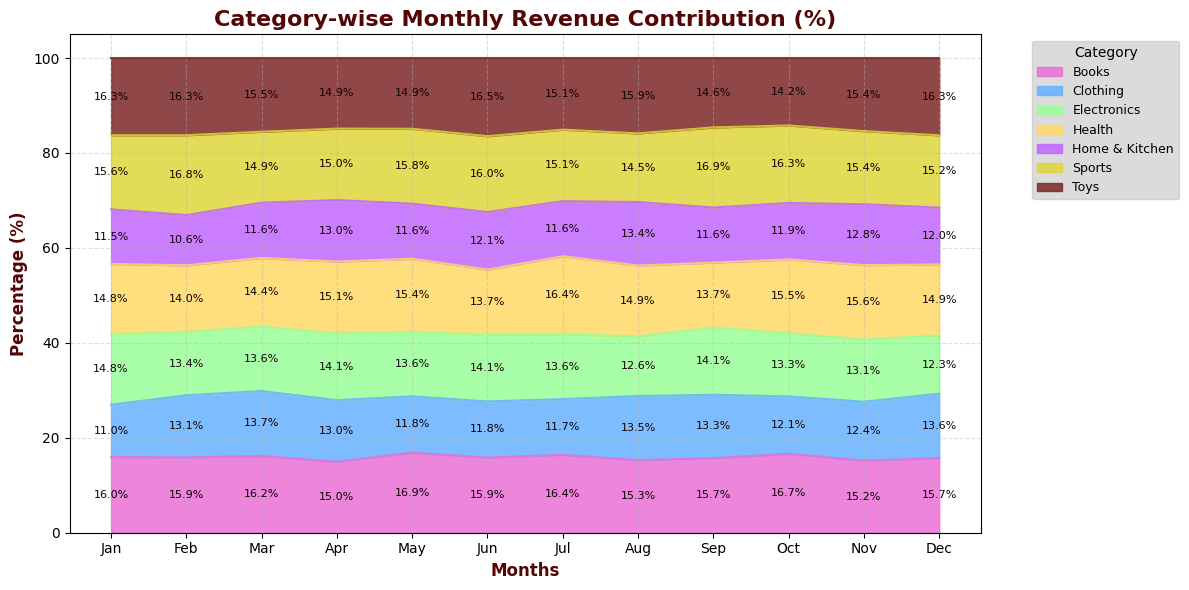

In [100]:

months_names = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 
                'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']


fig, ax = plt.subplots(figsize=(12, 6))


custom_colors = ["#EA70D6", '#66B2FF', '#99FF99', '#FFD966', '#C266FF',"#DED63B","#7D2727"]


category_monthly_percentage.T.plot(
    kind='area',
    ax=ax,
    color=custom_colors,
    alpha=0.85
)



plt.title('Category-wise Monthly Revenue Contribution (%)', fontsize=16, fontweight='bold',color="#540505")
plt.ylabel('Percentage (%)', fontsize=12, fontweight='bold',color="#540505")
plt.xlabel('Months', fontsize=12, fontweight='bold',color="#540505")
plt.xticks(range(len(months_names)), months_names, rotation=0,fontsize=10)

# --- Step 4: Add percentage labels inside each area ---
for month_idx, month in enumerate(category_monthly_percentage.columns):
    cumulative = 0
    for category in category_monthly_percentage.index:
        value = category_monthly_percentage.loc[category, month]
        cumulative += value
        ax.text(
            month_idx, cumulative - (value / 2),  # Position in middle of area
            f"{value:.1f}%", fontsize=8, ha='center', va='center', color="#0E0101"
        )


plt.grid(True, linestyle='--', alpha=0.4)
plt.legend(title="Category",fontsize=9,bbox_to_anchor=(1.05, 1), loc='upper left',frameon=True,facecolor='lightgray')
plt.tight_layout()
plt.show()


In [101]:
# Month name mapping (assuming months are in order Jan..Dec)
months_names = ['January', 'February', 'March', 'April', 'May', 'June', 
                'July', 'August', 'September', 'October', 'November', 'December']

# Extract months and categories from dataframe
months = category_monthly_percentage.columns.tolist()
categories = category_monthly_percentage.index.tolist()

# Soft custom color palette
custom_colors = [
    "#FF6F61", "#6B5B95", "#88B04B", "#F7CAC9",
    "#92A8D1", "#F7786B", "#034F84", "#98DDDE",
    "#EFC050", "#5B5EA6", "#55B4B0", "#E15D44"
]

# Create figure
fig = go.Figure()

# Add a bar trace for each month
for month_idx, month in enumerate(months):
    month_name = months_names[month_idx]  # Get full month name
    fig.add_trace(go.Bar(
        x=categories,
        y=category_monthly_percentage[month],
        name=month_name,  # Show full name in legend
        visible=(month_idx == 0),
        marker=dict(
            color=custom_colors,
            line=dict(width=2, color='white')  # Wedge/separation effect
        ),
        text=[f"{val:.1f}%" for val in category_monthly_percentage[month]],
        textposition="auto",
        hovertemplate="<b>%{x}</b><br>Month: " + month_name + "<br>Contribution: %{y:.1f}%<extra></extra>"
    ))

# Create dropdown buttons
buttons = []
for i, month_name in enumerate(months_names):
    visible = [False] * len(months_names)
    visible[i] = True
    buttons.append(dict(
        label=month_name,
        method="update",
        args=[{"visible": visible},
              {"title": f"<b>Category-wise Revenue Contribution (%) - {month_name}</b>"}]
    ))

# Layout styling
fig.update_layout(
    updatemenus=[dict(
        active=0,
        buttons=buttons,
        x=1.15,
        y=1.15,
        bgcolor="lightgray",
        bordercolor="black",
        borderwidth=1
    )],
    title=f"<b>Category-wise Revenue Contribution (%) - {months_names[0]}</b>",
    title_font=dict(size=22, family="Calibri", color="#150E3C"),
    xaxis_title="<b>Category</b>",
    yaxis_title="<b>Percentage (%)</b>",
    xaxis=dict(
        tickfont=dict(size=13, family="Calibri", color="#333333")
    ),
    yaxis=dict(
        tickfont=dict(size=13, family="Calibri", color="#333333"),
        gridcolor="lightgray"
    ),
    template="plotly_white",
    height=500,
    width=950,
    legend=dict(
        title="<b>Months</b>",
        font=dict(size=10, family="Calibri"),
        bgcolor="white",
        bordercolor="lightgray",
        borderwidth=1
    )
)

fig.show()

| **Line / Section** | **Purpose** | **Details** |
|--------------------|-------------|-------------|
| `months = category_monthly_percentage.columns.tolist()` | Extract months from DataFrame | Gets all column names (e.g., Jan, Feb, Mar...) as a Python list to use for dropdown menu and chart traces. |
| `categories = category_monthly_percentage.index.tolist()` | Extract categories from DataFrame | Gets all row names (e.g., Books, Clothing...) to be used as X-axis labels. |
| `custom_colors = [...]` | Custom bar colors | List of hex color codes that will be applied to bars to make the chart visually appealing. |
| `fig = go.Figure()` | Create Plotly figure | Initializes an empty figure to which we will add bar traces. |
| `for month in months:` | Loop through each month | We create a separate bar chart trace for each month. |
| `go.Bar(...)` | Create bar chart trace | Adds a single month's data as a bar chart, setting colors, labels, and hover text. |
| `visible=(month == months[0])` | Show only first month initially | Makes the first month's bars visible and hides others until selected from dropdown. |
| `marker_color=custom_colors` | Set bar colors | Applies our custom palette so each category gets a consistent color. |
| `text=[f"{val:.1f}%" ...]` | Add percentage labels on bars | Formats each bar value to one decimal place with a `%` sign. |
| `textposition="auto"` | Position labels automatically | Lets Plotly decide the best place for the labels on the bars. |
| `hovertemplate=...` | Custom hover tooltip | Shows category, month, and % neatly when hovering over a bar. |
| `buttons=[]` | Prepare dropdown buttons | List that will store button configurations for each month. |
| `visible = [False] * len(months)` | Hide all traces initially | Used for controlling which trace appears when a month is selected. |
| `visible[i] = True` | Show selected month | Sets the current month's trace to visible in dropdown action. |
| `args=[{"visible": visible}, {...}]` | Update chart on dropdown click | Updates both visible traces and chart title when month changes. |
| `fig.update_layout(...)` | Style chart layout | Controls title font, axis labels, grid color, background, dropdown style, legend style, etc. |
| `template="plotly_white"` | Chart theme | Gives chart a clean white background with minimal styling. |
| `legend=dict(...)` | Style legend | Sets legend font, background color, and border for neat appearance. |
| `fig.show()` | Display chart | Renders interactive chart in your notebook or browser. |


**INSIGHTS**
1. **Books category shows stable revenue share**: Books maintain a fairly consistent contribution between ~15%–17% across all months, showing a stable demand pattern.

2. **Sports & Toys lead in contribution**: Sports and Toys often appear at the top share range (~15%–17%) in most months, suggesting they are strong, high-performing categories.

3. **Electronics shows a slight decline**: Electronics starts with ~14.8% in month 1 but gradually dips closer to ~12% by the end of the year, which could indicate either reduced sales or increased competition from other categories.

4. **Clothing sees growth in the later months**: Clothing starts at ~11% in month 1, rises to over 13% in multiple months, especially month 8 and month 12, hinting at possible seasonal demand (e.g., festivals or sales events).

5. **Health category has noticeable spikes**: Health’s share peaks above 16% in month 7 and stays strong in months 10–11, which could be linked to seasonal health product demand or targeted promotions.

**Do most Products fall into low, medium, or high price ranges?**

In [102]:
print(f"Minimum Price: {df['price'].min()}")
print(f"Maximum Price: {df['price'].max()}")

Minimum Price: 7.29
Maximum Price: 499.86


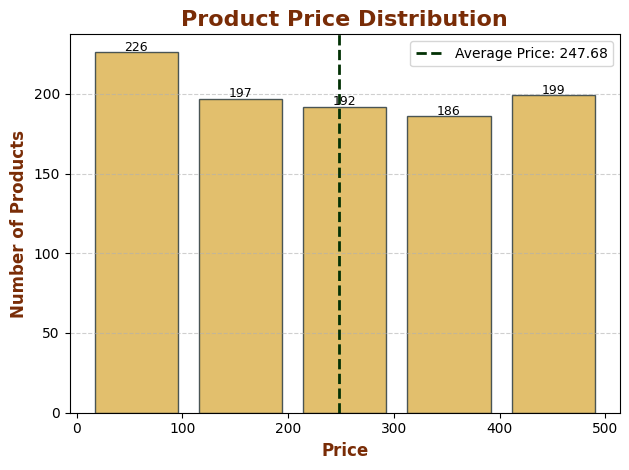

In [103]:
# Plot histogram with slimmer bars
counts, bins, patches = plt.hist(
    df['price'],
    bins=5,
    color="#D7A52F",
    edgecolor="#031B2B",
    alpha=0.7,
    rwidth=0.8   # Reduce bar width to 80% of bin width
)

# Add frequency labels on top of bars
for count, bin_left, bin_right in zip(counts, bins[:-1], bins[1:]):
    plt.text(
        (bin_left + bin_right) / 2,  # X position (center of bar)
        count + 1,                   # Y position (above bar)
        int(count),                  # Frequency text
        ha='center',
        fontsize=9,
        color="#050505"
    )

# Add average price line
avg_price = df['price'].mean()
plt.axvline(
    avg_price,
    color="#023104",
    linestyle='--',
    linewidth=2,
    label=f'Average Price: {avg_price:.2f}'
)

plt.title('Product Price Distribution', fontsize=16, fontweight='bold', color="#792C06")
plt.xlabel('Price', fontsize=12, fontweight='bold', color="#792C06")
plt.ylabel('Number of Products', fontsize=12, fontweight='bold', color="#792C06")
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()


**INSIGHTS**
* Most products are in the lowest price range (0–100) 226 products, which is higher than any other bin.

* Prices are fairly evenly spread across ranges, but 300–400 has the lowest count (186).

* Average price (~250) falls in the 200–300 range, yet the distribution suggests many products are still priced lower than average.

**Do most products have high customer ratings, or is there a significant share of poorly rated items?**

In [104]:
print(f"Minimum Review Score: {df['review_score'].min()}")
print(f"Maximum Review Score: {df['review_score'].max()}")

Minimum Review Score: 1.0
Maximum Review Score: 5.0


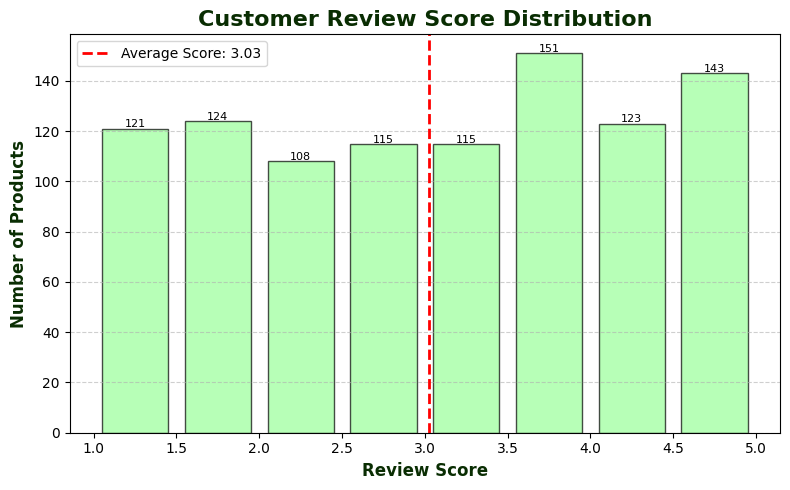

In [105]:
plt.figure(figsize=(8, 5))

# Define bins starting from 1 to 5 with step of 0.5
bins = np.arange(1, 5.0 + 0.5, 0.5)

# Plot histogram with reduced bar width
counts, bin_edges, patches = plt.hist(
    df['review_score'],
    bins=bins,
    color='#99FF99',
    edgecolor='black',
    alpha=0.7,
    rwidth=0.8   # Slimmer bars (80% of bin width)
)

# Average review score line
avg_score = df['review_score'].mean()
plt.axvline(
    avg_score,
    color='red',
    linestyle='--',
    linewidth=2,
    label=f'Average Score: {avg_score:.2f}'
)

# Annotate frequencies (positioned better for slimmer bars)
for count, bin_left, bin_right in zip(counts, bin_edges[:-1], bin_edges[1:]):
    if count > 0:
        plt.text(
            (bin_left + bin_right) / 2,  # Center of the bar
            count + 0.5,                 # Slightly above the bar
            int(count),
            ha='center',
            fontsize=8,
            color='black'
        )

# Titles & labels
plt.title('Customer Review Score Distribution', fontsize=16, fontweight='bold', color="#092D02")
plt.xlabel('Review Score', fontsize=12, color="#092D02", fontweight='bold')
plt.ylabel('Number of Products', fontsize=12, color="#092D02", fontweight='bold')
plt.xticks(bins)  # Show all bin edges

plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()



**Do most products receive a small number of reviews, or are reviews evenly spread across products?**

In [106]:
print(f"Minimum Review Count: {df['review_count'].min()}")
print(f"Maximum Review Count: {df['review_count'].max()}")

Minimum Review Count: 1
Maximum Review Count: 999


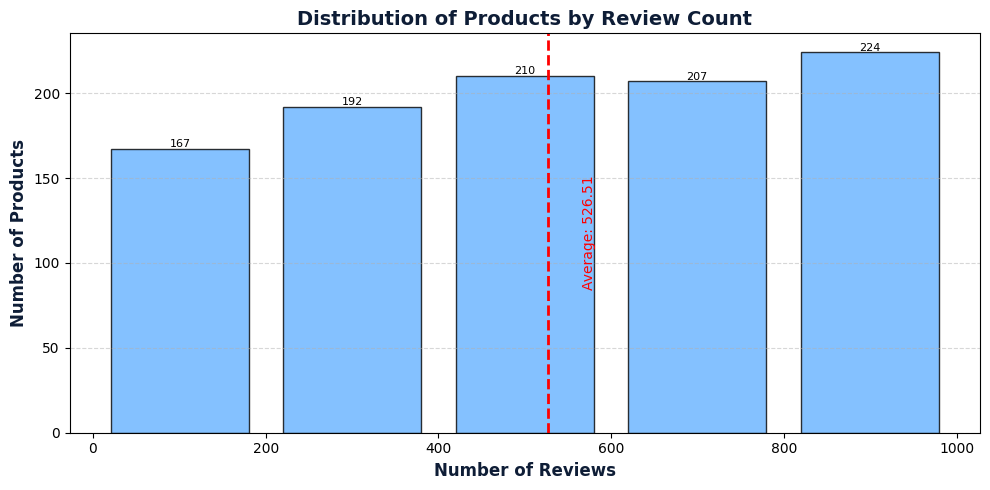

In [107]:
# Average review count
avg_reviews = df['review_count'].mean()

# Figure
plt.figure(figsize=(10, 5))

# Histogram with slimmer bars
counts, bin_edges, patches = plt.hist(
    df['review_count'],
    bins=5,
    edgecolor='black',
    color="#66B2FF",
    alpha=0.8,
    rwidth=0.8  # Slimmer bars (80% width)
)

# Average line + label
plt.axvline(avg_reviews, color='red', linestyle='--', linewidth=2)
plt.text(
    avg_reviews + (bin_edges[1] - bin_edges[0]) * 0.2,  # Slight offset from line
    plt.ylim()[1] * 0.5,                               # Halfway up the y-axis
    f'Average: {avg_reviews:.2f}',
    color='red',
    rotation=90,
    va='center',
    ha='left',
    fontsize=10
)

# Show frequency above bars
for count, bin_left, bin_right in zip(counts, bin_edges[:-1], bin_edges[1:]):
    plt.text(
        (bin_left + bin_right) / 2,  # Center of bar
        count + 1,                   # Slightly above bar
        str(int(count)),
        ha='center',
        fontsize=8
    )

# Labels & Title
plt.title('Distribution of Products by Review Count', fontsize=14, fontweight='bold', color="#0E1D36")
plt.xlabel('Number of Reviews', fontsize=12, fontweight='bold', color="#0E1D36")
plt.ylabel('Number of Products', fontsize=12, fontweight='bold', color="#0E1D36")

# Grid & Layout
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


**INSIGHTS**
* Most products fall into the 400–600 and 800–1000 review count ranges (210 and 224 products respectively).

* Products with fewer than 200 reviews are less common (only 167 products).

* The average review count (526.51) sits in the middle range, meaning many products are near or above this value.

**How Many Products Sold Within Each Unit Range in January?**

In [108]:
print(f"Minimum Sold Units: {df['sales_month_1'].min()}")
print(f"Maximum Sold Units: {df['sales_month_1'].max()}")

Minimum Sold Units: 0
Maximum Sold Units: 1000


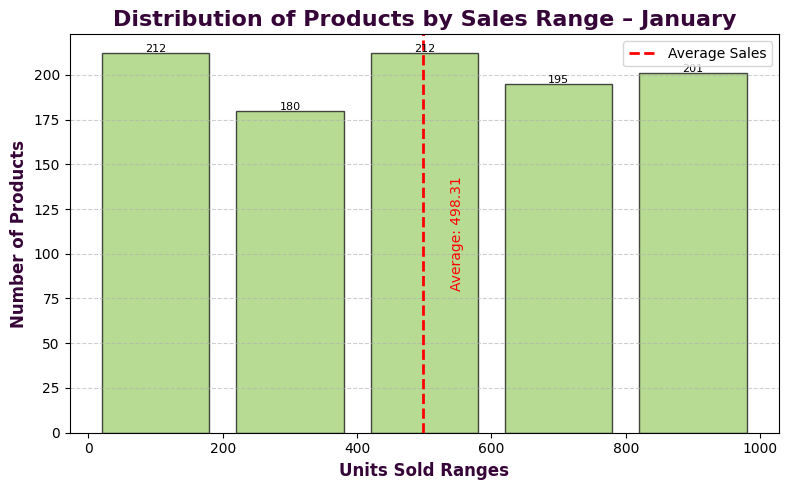

In [109]:
plt.figure(figsize=(8, 5))

# Histogram with slimmer bars
counts, bins, patches = plt.hist(
    df['sales_month_1'],
    bins=5,
    color='#99CC66',
    edgecolor='black',
    alpha=0.7,
    rwidth=0.8  # Slimmer bars
)

# Average line
avg_sales_month1 = df['sales_month_1'].mean()
plt.axvline(avg_sales_month1, color='red', linestyle='--', linewidth=2, label='Average Sales')
plt.text(
    avg_sales_month1 + (bins[1] - bins[0]) * 0.2,  # Offset from line
    plt.ylim()[1] * 0.5,                          # Middle of y-axis
    f'Average: {avg_sales_month1:.2f}',
    color='red',
    rotation=90,
    va='center',
    ha='left',
    fontsize=10
)

# Frequency labels (centered)
for count, bin_left, bin_right in zip(counts, bins[:-1], bins[1:]):
    if count > 0:
        plt.text(
            (bin_left + bin_right) / 2,  # Center of bar
            count + 0.5,                 # Above bar
            int(count),
            ha='center',
            fontsize=8,
            color='black'
        )

# Labels and title
plt.title('Distribution of Products by Sales Range – January', fontsize=16, fontweight='bold', color="#360538")
plt.xlabel('Units Sold Ranges', fontsize=12, fontweight='bold', color="#360538")
plt.ylabel('Number of Products', fontsize=12, fontweight='bold', color="#360538")

plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()


**How Many Products Sold Within Each Revenue Range in January?**

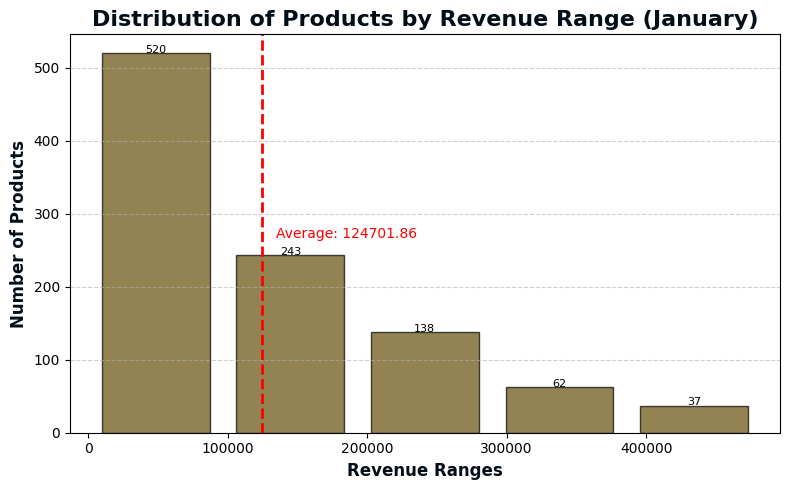

In [110]:
plt.figure(figsize=(8, 5))

# Histogram with slimmer bars
counts, bins, patches = plt.hist(
    df['Revenue_Product_month12'],
    bins=5,
    color="#654E0A",
    edgecolor='black',
    alpha=0.7,
    rwidth=0.8  # Slimmer bar width
)

# Average line
avg_revenue_month12 = df['Revenue_Product_month12'].mean()
plt.axvline(avg_revenue_month12, color='red', linestyle='--', linewidth=2)
plt.text(
    avg_revenue_month12 + (bins[1] - bins[0]) * 0.1,   # Offset from line
    plt.ylim()[1] * 0.5,                               # Midway up the chart
    f'Average: {avg_revenue_month12:.2f}',
    color='red',
    rotation=0,
    va='center',
    ha='left',
    fontsize=10
)

# Frequency labels (correct bin positioning)
for count, bin_left, bin_right in zip(counts, bins[:-1], bins[1:]):
    if count > 0:
        plt.text(
            (bin_left + bin_right) / 2,  # Center of bar
            count + 0.5,                 # Above bar
            int(count),
            ha='center',
            fontsize=8,
            color='black'
        )

# Labels and title
plt.title('Distribution of Products by Revenue Range (January)', fontsize=16, fontweight='bold', color="#030E18")
plt.xlabel('Revenue Ranges', fontsize=12, fontweight='bold', color="#030E18")
plt.ylabel('Number of Products', fontsize=12, fontweight='bold', color="#030E18")

plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()



**What is the Impact of Price on Sales?Do cheaper products sell more units?**

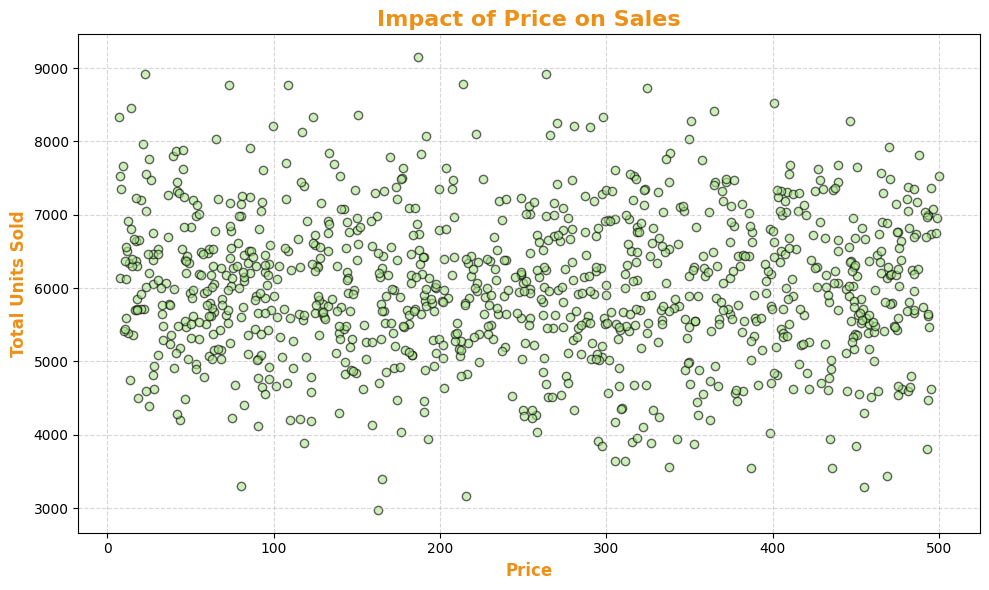

In [111]:
# Calculate total sales for each product
df['total_sales'] = df[[f'sales_month_{m}' for m in range(1, 13)]].sum(axis=1)

plt.figure(figsize=(10, 6))
plt.scatter(df['price'], df['total_sales'], alpha=0.6, c="#ACE68D", edgecolor="black")

plt.title("Impact of Price on Sales", fontsize=16, fontweight='bold', color="#EC9018")
plt.xlabel("Price", fontsize=12, fontweight='bold', color="#EC9018")
plt.ylabel("Total Units Sold", fontsize=12, fontweight='bold', color="#EC9018")

plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

**INSIGHTS**
* No correlation
* There is no major difference in sales volume for Higher and Lower Price Products but when price is between 400-500,the sales is slightly less at that point.
* No Trend found.

**Which price ranges bring in more revenue?**

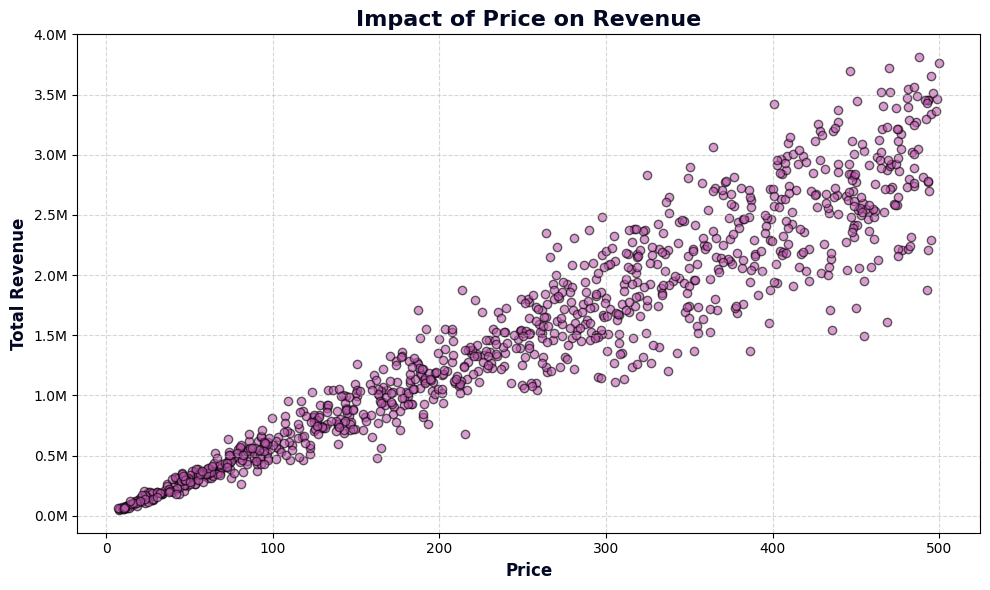

In [112]:
# Calculate total revenue for each product
df['total_revenue'] = df[[f'Revenue_Product_month{m}' for m in range(1, 13)]].sum(axis=1)

plt.figure(figsize=(10, 6))
plt.scatter(df['price'], df['total_revenue'], alpha=0.6, c="#C05AB0", edgecolor="black")
# Y-axis formatting: convert to millions
def to_millions(x, pos):
    return f'{x * 1e-6:.1f}M'

plt.gca().yaxis.set_major_formatter(ticker.FuncFormatter(to_millions))
plt.title("Impact of Price on Revenue", fontsize=16, fontweight='bold', color="#020724")
plt.xlabel("Price", fontsize=12, fontweight='bold', color="#020724")
plt.ylabel("Total Revenue", fontsize=12, fontweight='bold', color="#020724")

plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

**INSIGHTS**
* Positive Relationship
* Very cheap products have high sales but low total revenue.

* Mid-range prices may bring in good revenue.

* Expensive products might have low sales but still they bring the most Revenue.

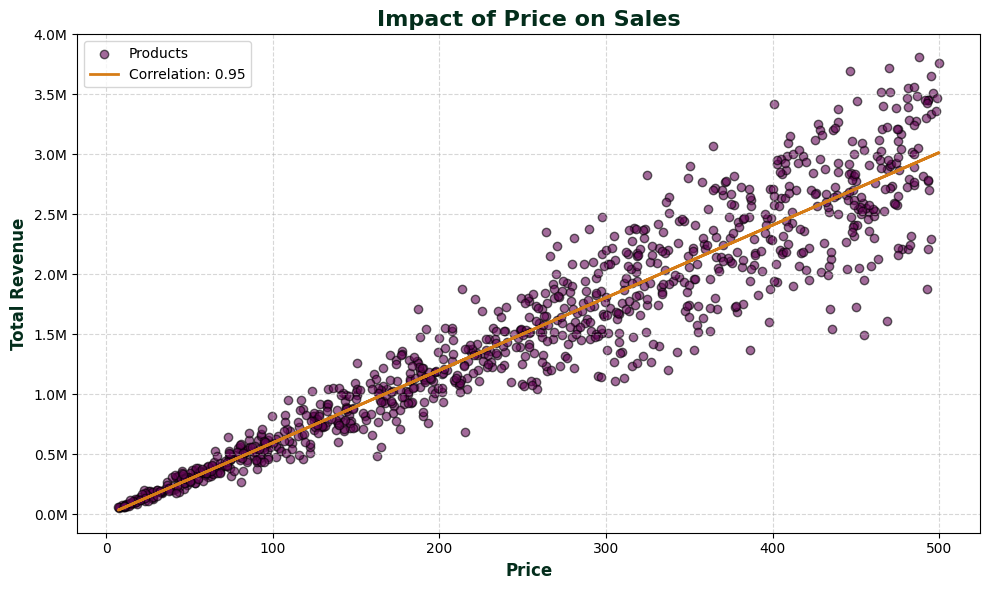

In [113]:
# Calculate correlation coefficient
corr_coef = np.corrcoef(df['price'], df['total_revenue'])[0, 1]

plt.figure(figsize=(10, 6))
plt.scatter(df['price'], df['total_revenue'], alpha=0.6, c="#650757", edgecolor="black", label="Products")

# Add trend line
z = np.polyfit(df['price'], df['total_revenue'], 1)  # Linear fit
p = np.poly1d(z)
plt.plot(df['price'], p(df['price']), color="#D67C16", linewidth=2, 
         label=f"Correlation: {corr_coef:.2f}")

# Y-axis formatting: convert to millions
def to_millions(x, pos):
    return f'{x * 1e-6:.1f}M'
plt.gca().yaxis.set_major_formatter(ticker.FuncFormatter(to_millions))

# Labels & Title
plt.title("Impact of Price on Sales", fontsize=16, fontweight='bold', color="#032D1B")
plt.xlabel("Price", fontsize=12, fontweight='bold', color="#032D1B")
plt.ylabel("Total Revenue", fontsize=12, fontweight='bold',color="#032D1B")

plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()


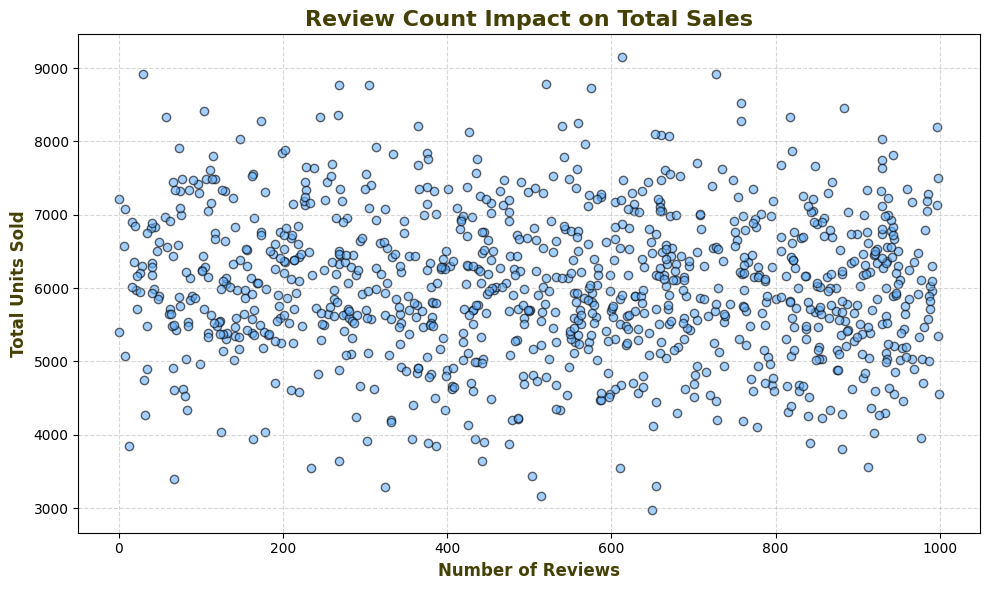

In [114]:
plt.figure(figsize=(10, 6))
plt.scatter(df['review_count'], df['total_sales'], alpha=0.6, c="#66B2FF", edgecolor="black")

plt.title("Review Count Impact on Total Sales", fontsize=16, fontweight='bold', color="#454106")
plt.xlabel("Number of Reviews", fontsize=12, fontweight='bold', color="#454106")
plt.ylabel("Total Units Sold", fontsize=12, fontweight='bold', color="#454106")

plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

**INSIGHTS**
* No Correlation 
* Review counts does not impact Total Units sold.

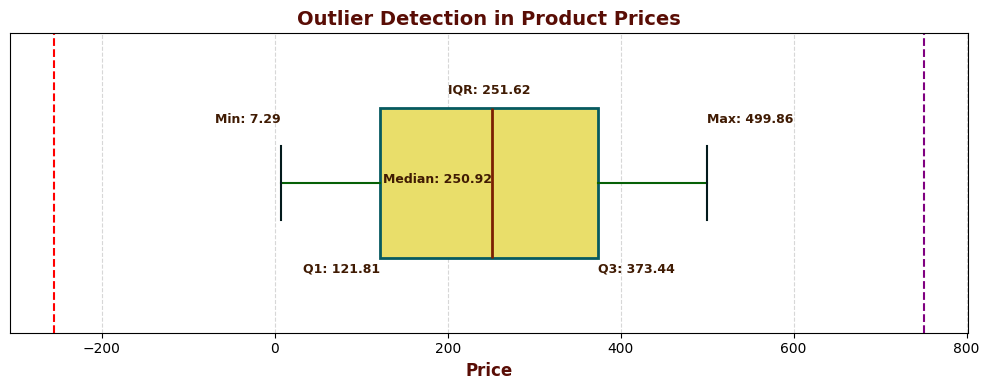

In [115]:
# Calculating required stats
q1 = df['price'].quantile(0.25)
q3 = df['price'].quantile(0.75)
iqr = q3 - q1
median = df['price'].median()
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr
min_val = df['price'][df['price'] >= lower_bound].min()
max_val = df['price'][df['price'] <= upper_bound].max()

# Plotting the boxplot
plt.figure(figsize=(10, 4))
bp = plt.boxplot(df['price'], vert=False, patch_artist=True, widths=0.5,
                 boxprops=dict(facecolor="#E9DE6A", color="#065A60", linewidth=2),
                 medianprops=dict(color="#7B2002", linewidth=2),
                 whiskerprops=dict(color="#066006", linewidth=1.5),
                 capprops=dict(color="#031A1C", linewidth=1.5),
                 flierprops=dict(marker='o', color="#343904", alpha=0.6))

# Add annotations for key stats
plt.text(q1, 0.7, f"Q1: {q1:.2f}", ha='right', fontsize=9, color='#401B03', fontweight='bold')
plt.text(q3, 0.7, f"Q3: {q3:.2f}", ha='left', fontsize=9, color='#401B03', fontweight='bold')
plt.text(median, 1.0, f"Median: {median:.2f}", ha='right', fontsize=9, color="#401B03", fontweight='bold')
plt.text(min_val, 1.2, f"Min: {min_val:.2f}", ha='right', fontsize=9, color='#401B03', fontweight='bold')
plt.text(max_val, 1.2, f"Max: {max_val:.2f}", ha='left', fontsize=9, color='#401B03', fontweight='bold')
plt.text((q1+q3)/2, 1.3, f"IQR: {iqr:.2f}", ha='center', fontsize=9, color='#401B03', fontweight='bold')
plt.axvline(lower_bound, color='red', linestyle='--', label=f'Lower Bound: {lower_bound:.2f}')
plt.axvline(upper_bound, color='purple', linestyle='--', label=f'Upper Bound: {upper_bound:.2f}')

# Title and labels
plt.title("Outlier Detection in Product Prices", fontsize=14, fontweight='bold', color="#590D05")
plt.xlabel("Price", fontsize=12, fontweight='bold', color="#590D05")

# Remove y-axis label and tick
plt.yticks([])  # removes the '1' on y-axis

plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

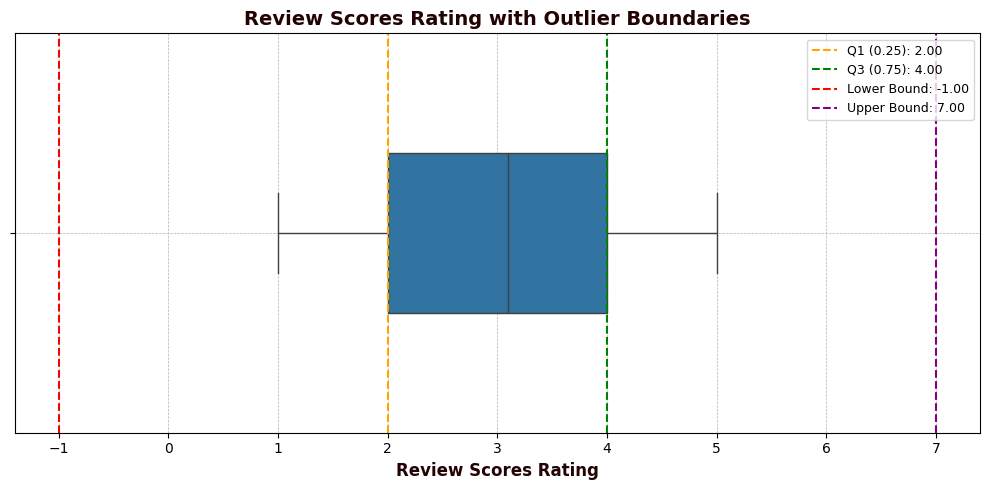

In [116]:
plt.figure(figsize=(10, 5))
sns.boxplot(x=df['review_score'], width=0.4)  # wider box

# Calculating bounds and key stats
q1 = df['review_score'].quantile(0.25)
q3 = df['review_score'].quantile(0.75)
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

# Adding lines for Q1, Q3, IQR bounds
plt.axvline(q1, color='orange', linestyle='--', label=f'Q1 (0.25): {q1:.2f}')
plt.axvline(q3, color='green', linestyle='--', label=f'Q3 (0.75): {q3:.2f}')
plt.axvline(lower_bound, color='red', linestyle='--', label=f'Lower Bound: {lower_bound:.2f}')
plt.axvline(upper_bound, color='purple', linestyle='--', label=f'Upper Bound: {upper_bound:.2f}')

# Add grid
plt.grid(True, linestyle='--', linewidth=0.5)

# Horizontal legend inside plot (top right)
plt.legend(loc='upper right', bbox_to_anchor=(1, 1), ncol=1, fontsize=9)

# Title and labels
plt.title('Review Scores Rating with Outlier Boundaries',fontweight='bold',color="#220202",fontsize=14)
plt.xlabel('Review Scores Rating',fontweight='bold',color="#220202",fontsize=12)

plt.tight_layout()
plt.show()

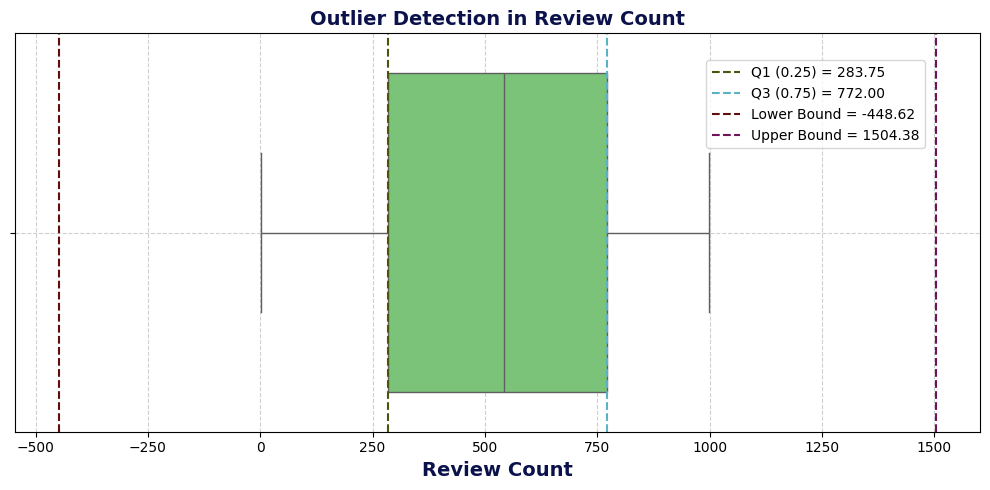

In [117]:
q1 = df['review_count'].quantile(0.25)
q3 = df['review_count'].quantile(0.75)
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

# Plot boxplot
plt.figure(figsize=(10, 5))
sns.boxplot(x=df['review_count'], color="#70CF6C")

# Add vertical lines with labels (including values)
plt.axvline(q1, color="#4A550B", linestyle='--', label=f'Q1 (0.25) = {q1:.2f}')
plt.axvline(q3, color="#59B2C6", linestyle='--', label=f'Q3 (0.75) = {q3:.2f}')
plt.axvline(lower_bound, color="#610D0D", linestyle='--', label=f'Lower Bound = {lower_bound:.2f}')
plt.axvline(upper_bound, color="#6E125A", linestyle='--', label=f'Upper Bound = {upper_bound:.2f}')

# Add grid
plt.grid(True, linestyle='--', alpha=0.6)

# Add horizontal legend inside the plot
plt.legend(loc='upper right', bbox_to_anchor=(0.95, 0.95), ncol=1, frameon=True)

# Title
plt.title("Outlier Detection in Review Count",fontweight='bold',color="#0A114B",fontsize=14)
plt.xlabel("Review Count",fontweight='bold',color="#0A114B",fontsize=14)
plt.tight_layout()
plt.show()

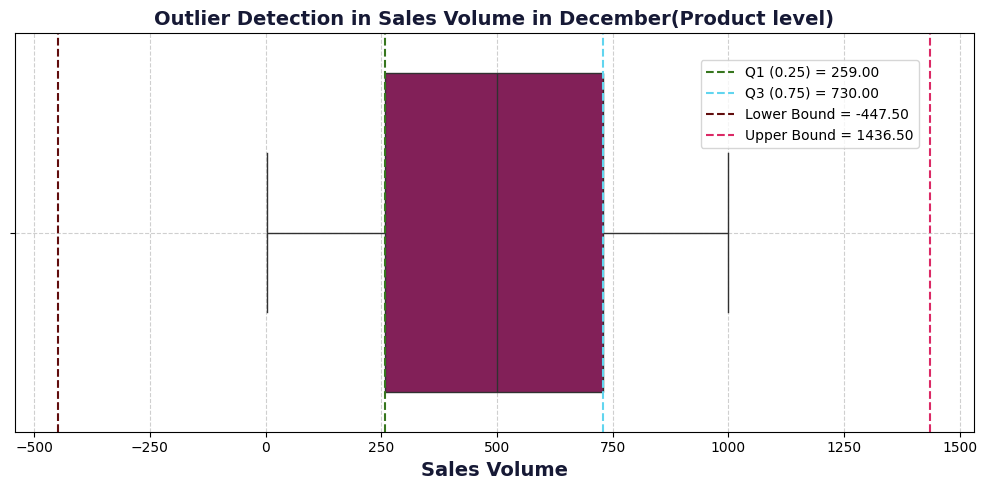

In [118]:
q1 = df['sales_month_12'].quantile(0.25)
q3 = df['sales_month_12'].quantile(0.75)
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

# Plot boxplot
plt.figure(figsize=(10,5))
sns.boxplot(x=df['sales_month_12'], color="#92105A")

# Add vertical lines with labels (including values)
plt.axvline(q1, color="#37761E", linestyle='--', label=f'Q1 (0.25) = {q1:.2f}')
plt.axvline(q3, color="#61D5EF", linestyle='--', label=f'Q3 (0.75) = {q3:.2f}')
plt.axvline(lower_bound, color="#610D0D", linestyle='--', label=f'Lower Bound = {lower_bound:.2f}')
plt.axvline(upper_bound, color="#DB2965", linestyle='--', label=f'Upper Bound = {upper_bound:.2f}')

# Add grid
plt.grid(True, linestyle='--', alpha=0.6)

# Add horizontal legend inside the plot
plt.legend(loc='upper right', bbox_to_anchor=(0.95, 0.95), ncol=1, frameon=True)

# Title
plt.title("Outlier Detection in Sales Volume in December(Product level)",fontweight='bold',color="#161935",fontsize=14)
plt.xlabel("Sales Volume",fontweight='bold',color="#161935",fontsize=14)
plt.tight_layout()
plt.show()

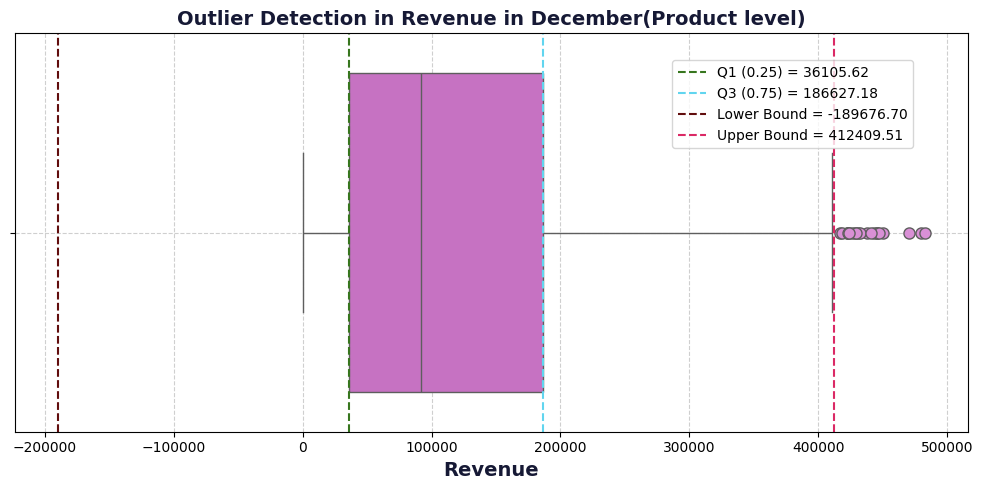

In [119]:
q1 = df['Revenue_Product_month12'].quantile(0.25)
q3 = df['Revenue_Product_month12'].quantile(0.75)
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

flierprops = dict(marker='o', markerfacecolor="#D990D6", markersize=8, linestyle='none')
# Plot boxplot
plt.figure(figsize=(10,5))
sns.boxplot(x=df['Revenue_Product_month12'], color="#D464CE",flierprops=flierprops)

# Add vertical lines with labels (including values)
plt.axvline(q1, color="#37761E", linestyle='--', label=f'Q1 (0.25) = {q1:.2f}')
plt.axvline(q3, color="#61D5EF", linestyle='--', label=f'Q3 (0.75) = {q3:.2f}')
plt.axvline(lower_bound, color="#610D0D", linestyle='--', label=f'Lower Bound = {lower_bound:.2f}')
plt.axvline(upper_bound, color="#DB2965", linestyle='--', label=f'Upper Bound = {upper_bound:.2f}')

# Add grid
plt.grid(True, linestyle='--', alpha=0.6)

# Add horizontal legend inside the plot
plt.legend(loc='upper right', bbox_to_anchor=(0.95, 0.95), ncol=1, frameon=True)

# Title
plt.title("Outlier Detection in Revenue in December(Product level)",fontweight='bold',color="#161935",fontsize=14)
plt.xlabel("Revenue",fontweight='bold',color="#161935",fontsize=14)
plt.tight_layout()
plt.show()